# Reproduction: Anomaly Detection in Real-Time Gross Settlement Systems

Data Wrangling (INFOMDW), Assignment 2.
Eralp Kurdas

This notebook reproduces the main experiment of

> R. Triepels, H. Daniels and R. Heijmans (2017). *Anomaly Detection in Real-Time Gross Settlement Systems.*

The paper trains two autoencoders on liquidity vectors from TARGET2, injects artificial bank runs into the test
data and checks whether the reconstruction error rises. The TARGET2 data is confidential, so the notebook first
generates a **synthetic dataset** with the same layout (20 banks, 8,561 fifteen-minute windows, about 2 million
payments, same split). Everything after the data (preprocessing, models, training, bank runs, metrics) follows the paper.

**Contents**
1. Parameters
2. Synthetic payment data
3. Preprocessing and the autoencoder
4. Learning-rate check
5. Grid search over the hidden-layer size (paper Figure 2)
6. Baseline error on the test set (paper Figure 3)
7. Bank-run simulation (paper Figures 4 and 5)
8. Sensitivity checks
9. Comparison with the paper

**Runtime.** About 10 minutes on a laptop with the default settings. The grid search (80 networks) and the
learning-rate check take about 75 minutes more; by default the notebook loads the values these exact cells
produced when they were run with `RUN_GRID = True` and `RUN_LR_CHECK = True`. Set those flags to `True` to recompute them.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")       # single-sample SGD runs faster single-threaded
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

# Switches for the slow parts
RUN_LR_CHECK = False   # ~5 min:  learning-rate check at l = 160 (Section 4)
RUN_GRID     = False   # ~70 min: 2 x 40 networks for Figure 2 (Section 5)
RUN_KAPPA_SWEEP = False  # ~3 min: injection-scale sweep (Section 8)
N_JOBS = 2             # parallel processes for the grid (Linux/macOS only; set 1 on Windows)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", None)   # show long table cells in full

## 1. Parameters

Values marked **[paper]** come from the paper. Values marked **[assumed]** are not given in the paper and were chosen
here. Values marked **[synthetic]** belong to the substitute data generator.

In [2]:
# ---------------- data layout [paper]
N_BANKS = 20               # twenty largest Dutch banks in TARGET2
N_INTERVALS = 8561         # 15-minute windows, January-October 2014
INTERVALS_PER_DAY = 28     # 196 windows = 7 operational days
N_HOLDOUT, N_TRAIN, N_TEST = 1680, 5081, 1800   # Jan-Feb / Mar-Aug / Sep-Oct, in time order
assert N_HOLDOUT + N_TRAIN + N_TEST == N_INTERVALS
TEST_START = N_HOLDOUT + N_TRAIN   # first test window (6761)
LAST = N_INTERVALS - 1             # last window (8560)

# ---------------- synthetic generator [synthetic]
DATA_SEED = 2014
TARGET_PAYMENTS = 2_000_000        # [paper] "about two million client payments"
BANK_SIZE_ZIPF = 1.5               # bank size s_r = 1 / r^1.5
GRAVITY_EXP = 0.8                  # rate_ij ~ (s_i s_j)^0.8 * affinity_ij
AFFINITY_SIGMA = 3.0               # lognormal spread of pair affinities
SPARSE_PAIR_PROB = 0.3             # share of pairs that never trade ...
SPARSE_PAIR_FACTOR = 0.0
BIG_BANKS_TRADE_ALL = 5            # ... except pairs involving the 5 largest banks
SELF_FLOW_FACTOR = 2.0             # a_ii: transfers between own accounts
AMOUNT_MEDIAN_EUR = 2.0e6          # median payment size of the largest bank
AMOUNT_SIZE_EXP = 0.3              # median scales with sender size^0.3
AMOUNT_SIGMA = 1.0                 # lognormal sigma of payment size
WEEKDAY_FACTORS = (1.10, 1.00, 0.95, 1.00, 1.05)   # Mon..Fri
BUSINESS_DAYS_PER_MONTH = 21
MONTH_END_FACTOR = 1.4             # last 2 business days of a month
DAY_NOISE_SIGMA = 0.15             # system-wide daily activity noise
PAIR_DAY_NOISE_SIGMA = 0.15        # pair-specific daily noise
N_LARGE_SHOCKS = 15                # isolated very large payments
LARGE_SHOCK_EUR = (2e8, 1e9)

# ---------------- autoencoder
INIT_VARIANCE = 0.1                # [paper] N(0, 0.1) initialisation
EPOCHS = 30                        # [paper]
BATCH_SIZE = 1                     # [assumed] plain SGD
LEARNING_RATE = {"linear": 0.05, "sigmoid": 0.2}   # [assumed] chosen on the holdout set (Section 4)
LR_CANDIDATES = (0.01, 0.05, 0.1, 0.2, 0.5)        # [assumed]
GRID_NEURONS = tuple(range(10, 401, 10))           # [paper]
CHOSEN_NEURONS = 160               # [paper]
TRAIN_SEED = 7                     # [assumed]
N_RANDOM_VECTORS = 1680            # [assumed] size of the uniform random set

# ---------------- bank runs
SUBJECT_BANK = 3                   # [paper] 4th row from the top in Fig. 5 (0-based index 3)
BANK_RUNS = {                      # [paper] Table 1
    "A": dict(d=196, r=2, ps=0.0, pe=0.8, lam_s=1e-4, lam_e=1e-7),
    "B": dict(d=196, r=6, ps=0.0, pe=0.8, lam_s=1e-4, lam_e=1e-7),
    "C": dict(d=392, r=2, ps=0.0, pe=0.8, lam_s=1e-4, lam_e=1e-7),
    "D": dict(d=392, r=6, ps=0.0, pe=0.8, lam_s=1e-4, lam_e=1e-7),
}
EPSILON = 0.5                      # [paper] threshold on the smoothed error
SMOOTH_WINDOW = 10                 # [paper] rolling average of ten windows
N_RUN_SEEDS = 20                   # [assumed] repetitions of each random bank run
FIG5_INTERVALS = (8528, 8529, 8530)  # [paper] windows shown in Fig. 5 (run C)

## 2. Synthetic payment data

The number of payments between two banks in a window is Poisson distributed. Its rate depends on the size of
both banks, a random pair affinity, the time of day (two peaks), the weekday, month ends and daily noise. Payment
amounts are lognormal. Fifteen isolated very large payments imitate the large-flow peak the paper reports in its
test set.

The generator was calibrated in four steps so that the baseline error of the 160-neuron linear autoencoder matches
the level in the paper's Figure 3 (roughly 0.2–0.8). It was never tuned on the bank-run results.

In [3]:
def intraday_profile(t):
    # Two activity peaks (morning, late afternoon) over the 28 windows of a day
    f = 0.3 + np.exp(-((t - 4) / 3.0) ** 2) + 0.8 * np.exp(-((t - 22) / 3.0) ** 2)
    return f / f.mean()


def generate(seed=DATA_SEED):
    rng = np.random.default_rng(seed)
    n, m, per_day = N_BANKS, N_INTERVALS, INTERVALS_PER_DAY

    # bank sizes (largest first) and pair affinities
    size = 1.0 / np.arange(1, n + 1) ** BANK_SIZE_ZIPF
    affinity = rng.lognormal(0.0, AFFINITY_SIGMA, (n, n))
    sparse = rng.random((n, n)) < SPARSE_PAIR_PROB
    big = np.arange(n) < BIG_BANKS_TRADE_ALL
    sparse[big, :] = False
    sparse[:, big] = False
    affinity[sparse] *= SPARSE_PAIR_FACTOR
    affinity[np.diag_indices(n)] = SELF_FLOW_FACTOR * rng.lognormal(0, 0.3, n)
    base = np.outer(size, size) ** GRAVITY_EXP * affinity

    # time modulation
    k = np.arange(m)
    day = k // per_day
    n_days = day[-1] + 1
    weekday = np.array(WEEKDAY_FACTORS)[np.arange(n_days) % 5]
    pos_in_month = np.arange(n_days) % BUSINESS_DAYS_PER_MONTH
    month_end = np.where(pos_in_month >= BUSINESS_DAYS_PER_MONTH - 2, MONTH_END_FACTOR, 1.0)
    day_noise = rng.lognormal(0.0, DAY_NOISE_SIGMA, n_days)
    time_factor = intraday_profile(k % per_day) * (weekday * month_end * day_noise)[day]
    pair_day_noise = rng.lognormal(0.0, PAIR_DAY_NOISE_SIGMA, (n_days, n, n))

    # scale so that the expected number of payments is about two million
    expected = (time_factor[:, None, None] * pair_day_noise[day]).sum(0)
    scale = TARGET_PAYMENTS / (expected * base).sum()
    rates = scale * base[None] * time_factor[:, None, None] * pair_day_noise[day]
    counts = rng.poisson(rates)                                   # (m, n, n)

    # lognormal payment amounts; the median scales mildly with sender size
    flat_idx = np.repeat(np.arange(counts.size), counts.ravel())
    sender = (flat_idx // n) % n
    mu = np.log(AMOUNT_MEDIAN_EUR * size[sender] ** AMOUNT_SIZE_EXP)
    amounts = rng.lognormal(mu, AMOUNT_SIGMA)
    A = np.bincount(flat_idx, weights=amounts, minlength=counts.size).reshape(m, n, n)

    # isolated very large payments
    for _ in range(N_LARGE_SHOCKS):
        kk, i, j = rng.integers(m), rng.integers(n), rng.integers(n)
        A[kk, i, j] += rng.uniform(*LARGE_SHOCK_EUR)
    return A, int(counts.sum())


A, n_payments = generate()     # A[k, i, j] = total amount bank i paid to bank j in window k (paper Eq. 1)
out = np.delete(A[:, SUBJECT_BANK, :], SUBJECT_BANK, axis=1)
print(f"windows: {A.shape[0]:,}   banks: {A.shape[1]}   payments: {n_payments:,}")
print(f"non-zero flows: {(A > 0).mean():.1%}")
print(f"stressed bank (bank {SUBJECT_BANK + 1}): {(out == 0).mean():.1%} of outgoing flows are zero, "
      f"mean non-zero flow EUR {out[out > 0].mean():,.0f}")

windows: 8,561   banks: 20   payments: 2,001,138
non-zero flows: 10.9%
stressed bank (bank 4): 85.6% of outgoing flows are zero, mean non-zero flow EUR 4,853,602


## 3. Preprocessing and the autoencoder

* **Liquidity vector (paper Eq. 2):** the columns of each $n\times n$ matrix are stacked into a vector of $n^2 = 400$ values.
* **Scaling (paper Section 4.1):** $\log(1+x)$, then min-max to $[0,1]$. The paper does not say whether scaling is per
  flow or global; here it is per flow, fitted on all 8,561 original vectors, because the paper normalises before splitting.
* **Autoencoder (paper Eqs. 4–11):** $\varphi(a) = f(W_1 a + b_1)$ and $\psi(h) = \mathrm{sigmoid}(W_2 h + b_2)$, with
  $f$ linear ("linear autoencoder") or sigmoid ("sigmoid autoencoder"). The loss is
  $\mathrm{RE}(a) = \tfrac12\lVert\psi(\varphi(a)) - a\rVert^2$, minimised with stochastic gradient descent.

In [4]:
def vectorize(A):
    # Paper Eq. 2: stack the columns; flow a_ij sits at position i + n*j
    m, n, _ = A.shape
    return A.transpose(0, 2, 1).reshape(m, n * n)


def unvectorize(v, n=N_BANKS):
    return v.reshape(-1, n, n).transpose(0, 2, 1)


class Scaler:
    # log(1 + x) followed by per-flow min-max scaling to [0, 1]
    def fit(self, V):
        L = np.log1p(V)
        self.lo, self.hi = L.min(0), L.max(0)
        return self

    def transform(self, V):
        rng = np.where(self.hi - self.lo > 0, self.hi - self.lo, 1.0)
        return (np.log1p(V) - self.lo) / rng


def split(X):
    h, t = N_HOLDOUT, N_HOLDOUT + N_TRAIN
    return X[:h], X[h:t], X[t:]


def sigmoid(z):
    return 0.5 * (1.0 + np.tanh(0.5 * z))   # numerically stable logistic function


class Autoencoder:
    def __init__(self, n_in, n_hidden, hidden="linear", seed=TRAIN_SEED, dtype=np.float32):
        rng = np.random.default_rng(seed)
        sd = np.sqrt(INIT_VARIANCE)
        self.dtype = dtype
        self.W1 = rng.normal(0, sd, (n_hidden, n_in)).astype(dtype)
        self.b1 = rng.normal(0, sd, n_hidden).astype(dtype)
        self.W2 = rng.normal(0, sd, (n_in, n_hidden)).astype(dtype)
        self.b2 = rng.normal(0, sd, n_in).astype(dtype)
        self.hidden, self.rng = hidden, rng

    def _encode(self, X):
        z = np.asarray(X, self.dtype) @ self.W1.T + self.b1
        return z if self.hidden == "linear" else sigmoid(z)

    def reconstruct(self, X):
        return sigmoid(self._encode(X) @ self.W2.T + self.b2)

    def flow_errors(self, X):          # paper Eq. 8
        X = np.asarray(X, self.dtype)
        return (0.5 * (self.reconstruct(X) - X) ** 2).astype(np.float64)

    def errors(self, X):               # paper Eq. 9
        return self.flow_errors(X).sum(1)

    def mre(self, X):                  # paper Eq. 10
        return float(self.errors(X).mean())

    def fit(self, X, epochs=EPOCHS, lr=None, batch_size=BATCH_SIZE):
        lr = self.dtype(LEARNING_RATE[self.hidden] if lr is None else lr)
        X = np.asarray(X, self.dtype)
        W1, b1, W2, b2 = self.W1, self.b1, self.W2, self.b2
        lin = self.hidden == "linear"
        for _ in range(epochs):
            order = self.rng.permutation(len(X))
            for s in range(0, len(X), batch_size):
                x = X[order[s:s + batch_size]]
                z = x @ W1.T + b1
                h = z if lin else sigmoid(z)
                y = sigmoid(h @ W2.T + b2)
                dy = (y - x) * y * (1.0 - y)        # gradient at the output pre-activation
                dh = dy @ W2
                if not lin:
                    dh *= h * (1.0 - h)
                W2 -= lr * (dy.T @ h); b2 -= lr * dy.sum(0)
                W1 -= lr * (dh.T @ x); b1 -= lr * dh.sum(0)
        return self


V = vectorize(A)
scaler = Scaler().fit(V)
X = scaler.transform(V)
holdout, train, test = split(X)
rnd = np.random.default_rng(TRAIN_SEED + 1).random((N_RANDOM_VECTORS, X.shape[1]))   # uniform random set
LOWER_BOUND = N_BANKS ** 2 / 24                                                       # paper Eq. 14
print("holdout / train / test:", holdout.shape, train.shape, test.shape)
print(f"random-set lower bound n^2/24 = {LOWER_BOUND:.2f}")

holdout / train / test: (1680, 400) (5081, 400) (1800, 400)
random-set lower bound n^2/24 = 16.67


**Gradient check.** The analytic gradient of the training step is compared with a numerical one on a tiny network.

In [5]:
for hidden in ("linear", "sigmoid"):
    x = np.random.default_rng(0).random((1, 6))
    ae = Autoencoder(6, 3, hidden, seed=1, dtype=np.float64)
    numeric, eps = np.zeros_like(ae.W1), 1e-6
    for idx in np.ndindex(ae.W1.shape):
        ae.W1[idx] += eps; up = ae.errors(x)[0]
        ae.W1[idx] -= 2 * eps; down = ae.errors(x)[0]
        ae.W1[idx] += eps
        numeric[idx] = (up - down) / (2 * eps)
    ae2 = Autoencoder(6, 3, hidden, seed=1, dtype=np.float64)
    W_before = ae2.W1.copy()
    ae2.rng = np.random.default_rng(0)
    ae2.fit(x, epochs=1, lr=1.0)
    print(f"{hidden:8s} max |analytic - numeric| = {np.abs((W_before - ae2.W1) - numeric).max():.1e}")

linear   max |analytic - numeric| = 5.2e-11
sigmoid  max |analytic - numeric| = 5.0e-11


## 4. Learning-rate check

The paper uses a fixed learning rate but does not report it. Five rates are tried at $l = 160$ and the one with the
lowest holdout error is used for each network (linear diverges at 0.2, so 0.05 is used for it; its holdout error is
within 1% of 0.1).

In [6]:
LR_RESULTS_CSV = '''
model,neurons,lr,train_mre,holdout_mre,random_mre
linear,160,0.01,1.76449,1.75667,60.65714
linear,160,0.05,0.55798,0.59148,56.26776
linear,160,0.1,0.56625,0.58617,54.3066
linear,160,0.2,12.21129,12.10299,65.73535
linear,160,0.5,18.90739,18.82501,66.40554
sigmoid,160,0.01,0.89481,0.90863,52.6084
sigmoid,160,0.05,0.36618,0.41181,50.67171
sigmoid,160,0.1,0.26565,0.32029,49.80121
sigmoid,160,0.2,0.18606,0.25482,48.19062
sigmoid,160,0.5,0.20642,0.31534,47.39405
'''

def train_and_score(hidden, l, lr):
    ae = Autoencoder(train.shape[1], l, hidden).fit(train, lr=lr)
    return dict(model=hidden, neurons=l, lr=lr, train_mre=ae.mre(train),
                holdout_mre=ae.mre(holdout), random_mre=ae.mre(rnd))

if RUN_LR_CHECK:
    t0 = time.time()
    lr_results = pd.DataFrame([train_and_score(h, CHOSEN_NEURONS, lr)
                               for h in ("linear", "sigmoid") for lr in LR_CANDIDATES])
    print(f"done in {time.time() - t0:.0f} s")
else:
    lr_results = pd.read_csv(StringIO(LR_RESULTS_CSV.strip()))
    print("Loaded stored results (set RUN_LR_CHECK = True to recompute).")
lr_results.round(3)

Loaded stored results (set RUN_LR_CHECK = True to recompute).


,model,neurons,lr,train_mre,holdout_mre,random_mre
0,linear,160,0.01,1.764,1.757,60.657
1,linear,160,0.05,0.558,0.591,56.268
2,linear,160,0.10,0.566,0.586,54.307
3,linear,160,0.20,12.211,12.103,65.735
4,linear,160,0.50,18.907,18.825,66.406
5,sigmoid,160,0.01,0.895,0.909,52.608
6,sigmoid,160,0.05,0.366,0.412,50.672
7,sigmoid,160,0.10,0.266,0.320,49.801
8,sigmoid,160,0.20,0.186,0.255,48.191
9,sigmoid,160,0.50,0.206,0.315,47.394


## 5. Grid search over the hidden-layer size (paper Figure 2)

Networks with $l = 10, 20, \dots, 400$ hidden neurons are trained and scored on the holdout set and on 1,680 uniform
random vectors. On random data the best possible error is the lower bound $n^2/24 = 16.67$; a network below it
would be copying (memorising) its input.

In [7]:
GRID_RESULTS_CSV = '''
model,neurons,lr,train_mre,holdout_mre,random_mre
linear,10,0.05,4.24916,4.28552,36.48726
linear,20,0.05,3.3292,3.40032,47.05779
linear,30,0.05,2.50155,2.61753,46.98358
linear,40,0.05,1.9242,2.10422,49.01555
linear,50,0.05,1.46424,1.63517,50.61312
linear,60,0.05,1.14947,1.27688,54.86353
linear,70,0.05,0.9707,1.08847,56.3372
linear,80,0.05,0.83179,0.9363,55.91497
linear,90,0.05,0.80565,0.8487,54.50272
linear,100,0.05,0.71933,0.75095,53.93548
linear,110,0.05,0.62817,0.66897,54.72856
linear,120,0.05,0.60126,0.63002,55.55494
linear,130,0.05,0.60476,0.63158,57.10818
linear,140,0.05,0.56752,0.596,57.13187
linear,150,0.05,0.55783,0.58419,57.84098
linear,160,0.05,0.55798,0.59148,56.26776
linear,170,0.05,0.62044,0.63349,56.57069
linear,180,0.05,0.64795,0.66447,56.49771
linear,190,0.05,0.60572,0.63034,57.31484
linear,200,0.05,0.67397,0.70769,57.42648
linear,210,0.05,0.66716,0.69671,58.03893
linear,220,0.05,0.75893,0.77334,57.51458
linear,230,0.05,0.54189,0.57714,58.08752
linear,240,0.05,0.73446,0.75823,57.67169
linear,250,0.05,0.80784,0.84451,58.4918
linear,260,0.05,0.88438,0.90171,58.67076
linear,270,0.05,0.79928,0.81375,58.7334
linear,280,0.05,0.86658,0.89809,58.68897
linear,290,0.05,1.212,1.22503,59.70332
linear,300,0.05,0.81864,0.84313,59.86045
linear,310,0.05,0.95764,0.98337,59.18748
linear,320,0.05,1.10411,1.11139,59.56132
linear,330,0.05,1.12775,1.11915,60.17282
linear,340,0.05,1.25255,1.2854,60.06609
linear,350,0.05,1.20206,1.21847,60.0749
linear,360,0.05,1.47811,1.47892,60.64143
linear,370,0.05,1.52724,1.53712,60.57709
linear,380,0.05,1.52602,1.53729,59.88541
linear,390,0.05,1.49329,1.49437,60.04061
linear,400,0.05,1.67375,1.70199,60.93532
sigmoid,10,0.2,4.27685,4.30645,52.30425
sigmoid,20,0.2,3.49494,3.57676,47.3082
sigmoid,30,0.2,2.78151,2.89619,53.32258
sigmoid,40,0.2,2.20065,2.36059,52.04638
sigmoid,50,0.2,1.68739,1.87221,48.92098
sigmoid,60,0.2,1.35045,1.56347,46.04493
sigmoid,70,0.2,1.01592,1.23553,46.53716
sigmoid,80,0.2,0.73736,0.93697,44.19118
sigmoid,90,0.2,0.57893,0.76062,46.20242
sigmoid,100,0.2,0.47302,0.62326,45.17769
sigmoid,110,0.2,0.36828,0.50106,46.13104
sigmoid,120,0.2,0.2919,0.39977,48.15288
sigmoid,130,0.2,0.27473,0.35672,49.28772
sigmoid,140,0.2,0.23055,0.31755,48.49517
sigmoid,150,0.2,0.20281,0.27526,49.27321
sigmoid,160,0.2,0.18606,0.25482,48.19062
sigmoid,170,0.2,0.1714,0.23593,48.05106
sigmoid,180,0.2,0.17052,0.2296,48.02943
sigmoid,190,0.2,0.16577,0.22625,47.70257
sigmoid,200,0.2,0.15478,0.21263,48.93956
sigmoid,210,0.2,0.14101,0.20038,48.26968
sigmoid,220,0.2,0.14912,0.20434,47.38262
sigmoid,230,0.2,0.14233,0.19189,48.26077
sigmoid,240,0.2,0.15031,0.20031,47.08489
sigmoid,250,0.2,0.1321,0.18166,48.76293
sigmoid,260,0.2,0.13962,0.18982,48.97898
sigmoid,270,0.2,0.13263,0.18003,48.54229
sigmoid,280,0.2,0.13068,0.18099,48.7051
sigmoid,290,0.2,0.13048,0.18293,47.69732
sigmoid,300,0.2,0.1218,0.17267,48.69167
sigmoid,310,0.2,0.12739,0.17726,48.36879
sigmoid,320,0.2,0.12774,0.17721,48.23228
sigmoid,330,0.2,0.13053,0.17577,49.09155
sigmoid,340,0.2,0.1229,0.17117,48.89535
sigmoid,350,0.2,0.11825,0.16965,48.62559
sigmoid,360,0.2,0.12055,0.16718,48.40781
sigmoid,370,0.2,0.1235,0.17023,49.08631
sigmoid,380,0.2,0.11447,0.16147,47.7305
sigmoid,390,0.2,0.11219,0.16098,48.40369
sigmoid,400,0.2,0.1144,0.16395,49.76042
'''

def _grid_job(args):
    return train_and_score(*args)

if RUN_GRID:
    t0 = time.time()
    jobs = [(h, l, LEARNING_RATE[h]) for l in sorted(GRID_NEURONS, reverse=True) for h in ("linear", "sigmoid")]
    if N_JOBS > 1:
        import multiprocessing as mp
        with mp.get_context("fork").Pool(N_JOBS) as pool:
            rows = pool.map(_grid_job, jobs)
    else:
        rows = [_grid_job(j) for j in jobs]
    grid = pd.DataFrame(rows).sort_values(["model", "neurons"]).reset_index(drop=True)
    print(f"done in {(time.time() - t0) / 60:.0f} min")
else:
    grid = pd.read_csv(StringIO(GRID_RESULTS_CSV.strip()))
    print("Loaded stored results (set RUN_GRID = True to recompute).")

sizes = [10, 20, 40, 80, 120, 160, 200, 300, 400]
grid[grid.neurons.isin(sizes)].pivot(index="neurons", columns="model",
                                     values=["holdout_mre", "random_mre"]).round(3)

Loaded stored results (set RUN_GRID = True to recompute).


holdout_mre         random_mre        
model        linear sigmoid     linear sigmoid
neurons                                       
10            4.286   4.306     36.487  52.304
20            3.400   3.577     47.058  47.308
40            2.104   2.361     49.016  52.046
80            0.936   0.937     55.915  44.191
120           0.630   0.400     55.555  48.153
160           0.591   0.255     56.268  48.191
200           0.708   0.213     57.426  48.940
300           0.843   0.173     59.860  48.692
400           1.702   0.164     60.935  49.760

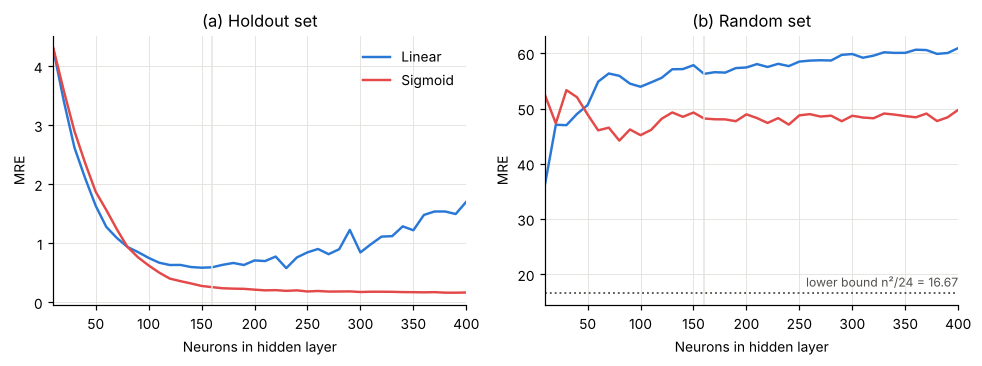

In [8]:
LINEAR, SIGMOID = "#2a78d6", "#e34948"   # blue = linear network, red = sigmoid network
INK, MUTED, GRIDC = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.6,
                     "legend.frameon": False, "figure.dpi": 110})

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4))
for ax, col, title in [(axes[0], "holdout_mre", "(a) Holdout set"), (axes[1], "random_mre", "(b) Random set")]:
    for h, c in [("linear", LINEAR), ("sigmoid", SIGMOID)]:
        d = grid[grid.model == h].sort_values("neurons")
        ax.plot(d.neurons, d[col], color=c, lw=1.6, label=h.capitalize())
    ax.axvline(CHOSEN_NEURONS, color=GRIDC, lw=1)
    ax.set(xlabel="Neurons in hidden layer", ylabel="MRE", title=title, xlim=(10, 400))
axes[1].axhline(LOWER_BOUND, color=MUTED, ls=":", lw=1.2)
axes[1].annotate(f"lower bound n²/24 = {LOWER_BOUND:.2f}", (400, LOWER_BOUND), xytext=(0, 4),
                 textcoords="offset points", ha="right", color=MUTED, fontsize=8)
axes[0].legend()
plt.tight_layout(); plt.show()

## 6. Baseline error on the test set (paper Figure 3)

The two networks with $l = 160$ are trained once and scored on the unmanipulated test set. The error per window is
smoothed with a trailing rolling mean of 10 windows. Besides the paper's threshold $\varepsilon = 0.5$, a second
threshold is set at the 99.5th percentile of the smoothed holdout error, because $\varepsilon = 0.5$ depends on the
error level of the original data.

trained both networks in 101 s

linear   MRE train 0.558  holdout 0.591  test 0.572 | smoothed test error mean 0.572, max 1.374 | holdout q99.5 threshold 1.212
sigmoid  MRE train 0.186  holdout 0.255  test 0.249 | smoothed test error mean 0.249, max 0.598 | holdout q99.5 threshold 0.581


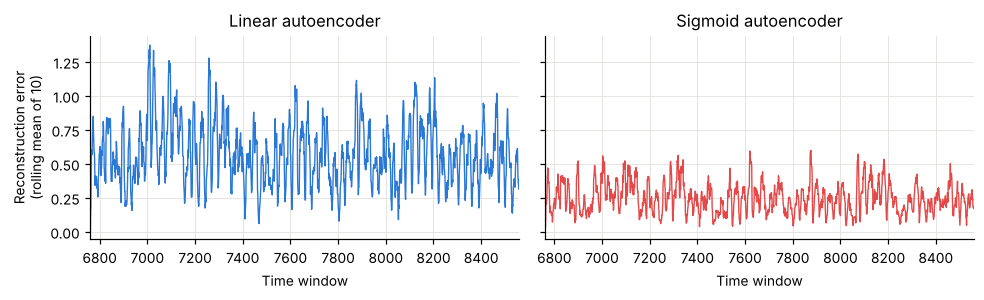

In [9]:
def smooth(e):
    return pd.Series(e).rolling(SMOOTH_WINDOW, min_periods=1).mean().to_numpy()

t0 = time.time()
models = {h: Autoencoder(train.shape[1], CHOSEN_NEURONS, h).fit(train) for h in ("linear", "sigmoid")}
print(f"trained both networks in {time.time() - t0:.0f} s\n")

base, thresholds = {}, {}
for h, ae in models.items():
    base[h] = smooth(ae.errors(test))
    thresholds[h] = {"paper eps=0.5": EPSILON,
                     "holdout q99.5": float(np.quantile(smooth(ae.errors(holdout)), 0.995))}
    print(f"{h:8s} MRE train {ae.mre(train):.3f}  holdout {ae.mre(holdout):.3f}  test {ae.mre(test):.3f} | "
          f"smoothed test error mean {base[h].mean():.3f}, max {base[h].max():.3f} | "
          f"holdout q99.5 threshold {thresholds[h]['holdout q99.5']:.3f}")

x_test = np.arange(TEST_START, N_INTERVALS)
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharey=True)
for ax, h, c in [(axes[0], "linear", LINEAR), (axes[1], "sigmoid", SIGMOID)]:
    ax.plot(x_test, base[h], color=c, lw=0.9)
    ax.set(title=f"{h.capitalize()} autoencoder", xlabel="Time window", xlim=(TEST_START, LAST))
axes[0].set_ylabel("Reconstruction error\n(rolling mean of 10)")
plt.tight_layout(); plt.show()

## 7. Bank-run simulation (paper Figures 4 and 5)

Following paper Eqs. 15–17 and Table 1, extra money is added to the stressed bank's payments to the 19 other banks.
In each window $x$ of the run, $P(x) \sim \text{Bernoulli}(p_x)$ decides whether money is added and
$C(x) \sim \text{Exponential}(\lambda_x)$ is the amount, with
$p_x = p_s + (p_e - p_s)\left(\tfrac{x-s}{d}\right)^r$ and $\lambda_x = \lambda_s + (\lambda_e - \lambda_s)\left(\tfrac{x-s}{d}\right)^r$.
Each run ends at the last test window ($s = 8560 - d$).

Equation 15 has no index for the receiving bank, so it is unclear whether all 19 flows get the same amount. The default
(`shared`) uses one draw per window for all 19 flows; `per_flow` draws separately for each receiving bank (Section 8).
Every run is repeated with 20 random seeds.

**Detection metrics** (per run and seed, then averaged):
* `false_alarm`: share of test windows before the run whose smoothed error is above the threshold
* `first_detect`: windows from the run start to the first window where the manipulated error is above the threshold
  *and* the original error at that window is not (only crossings caused by the run count)
* `flagged`: share of run windows above the threshold
* `last_day_ratio`: mean smoothed error over the last 28 windows divided by the original error over the same windows

In [10]:
def inject_bank_run(A_test, run, rng, draw="shared", bank=SUBJECT_BANK, kappa=1.0):
    A_run = A_test.copy()
    d, r = run["d"], run["r"]
    s = LAST - d
    others = np.array([j for j in range(A_run.shape[1]) if j != bank])
    for x in range(s, LAST + 1):
        frac = ((x - s) / d) ** r
        p = run["ps"] + (run["pe"] - run["ps"]) * frac               # paper Eq. 16
        lam = run["lam_s"] + (run["lam_e"] - run["lam_s"]) * frac    # paper Eq. 17
        if draw == "shared":
            add = rng.binomial(1, p) * rng.exponential(1.0 / lam)
        else:
            add = rng.binomial(1, p, len(others)) * rng.exponential(1.0 / lam, len(others))
        A_run[x - TEST_START, bank, others] += kappa * add          # paper Eq. 15
    return A_run, s


def detection_stats(sm, base_sm, s, eps):
    run, base_run = sm[s - TEST_START:], base_sm[s - TEST_START:]
    hit = np.flatnonzero((run >= eps) & (base_run < eps))
    return dict(first_detect=(int(hit[0]) if hit.size else np.nan),
                flagged=float((run >= eps).mean()),
                last_day_ratio=float(run[-INTERVALS_PER_DAY:].mean() / base_run[-INTERVALS_PER_DAY:].mean()))


A_test = A[TEST_START:]

def run_experiment(draw="shared", bank=SUBJECT_BANK, kappa=1.0, keep_curves=False):
    records, curves, fig5 = [], {}, None
    for name, run in BANK_RUNS.items():
        for seed in range(N_RUN_SEEDS):
            rng = np.random.default_rng(1000 * (ord(name) - 64) + seed)
            A_run, s = inject_bank_run(A_test, run, rng, draw, bank, kappa)
            Xr = scaler.transform(vectorize(A_run))
            for h, ae in models.items():
                sm = smooth(ae.errors(Xr))
                if keep_curves and seed == 0:
                    curves[(name, h)] = sm
                    if name == "C" and h == "linear":
                        fig5 = unvectorize(ae.flow_errors(Xr[[k - TEST_START for k in FIG5_INTERVALS]]))
                for tname, eps in thresholds[h].items():
                    records.append(dict(run=name, model=h, threshold=tname, eps=eps, seed=seed,
                                        false_alarm=float((base[h][: s - TEST_START] >= eps).mean()),
                                        **detection_stats(sm, base[h], s, eps)))
    df = pd.DataFrame(records)
    summary = (df.groupby(["threshold", "model", "run"])
                 .agg(eps=("eps", "first"), false_alarm=("false_alarm", "first"),
                      detected=("first_detect", lambda v: int(v.notna().sum())),
                      first_detect_mean=("first_detect", "mean"), first_detect_sd=("first_detect", "std"),
                      flagged=("flagged", "mean"), last_day_ratio=("last_day_ratio", "mean"))
                 .reset_index())
    summary["first_detect_days"] = summary.first_detect_mean / INTERVALS_PER_DAY
    return summary, curves, fig5


t0 = time.time()
summary_shared, curves, _ = run_experiment("shared", keep_curves=True)
print(f"done in {time.time() - t0:.0f} s  (detected = number of the {N_RUN_SEEDS} seeds with an alarm)")
summary_shared.round(3)

done in 2 s  (detected = number of the 20 seeds with an alarm)


,threshold,model,run,eps,false_alarm,detected,first_detect_mean,first_detect_sd,flagged,last_day_ratio,first_detect_days
0,holdout q99.5,linear,A,1.212,0.011,20,80.25,17.063,0.442,7.405,2.866
1,holdout q99.5,linear,B,1.212,0.011,20,140.45,19.779,0.157,4.576,5.016
2,holdout q99.5,linear,C,1.212,0.012,20,146.50,32.268,0.426,9.196,5.232
3,holdout q99.5,linear,D,1.212,0.012,20,271.75,24.645,0.184,6.583,9.705
4,holdout q99.5,sigmoid,A,0.581,0.003,20,75.10,14.249,0.526,9.866,2.682
5,holdout q99.5,sigmoid,B,0.581,0.003,20,132.20,20.895,0.223,6.048,4.721
6,holdout q99.5,sigmoid,C,0.581,0.004,20,110.50,36.890,0.518,12.187,3.946
7,holdout q99.5,sigmoid,D,0.581,0.004,20,258.80,32.557,0.236,8.777,9.243
8,paper eps=0.5,linear,A,0.500,0.597,20,53.90,21.309,0.836,7.405,1.925
9,paper eps=0.5,linear,B,0.500,0.597,20,122.95,24.252,0.692,4.576,4.391


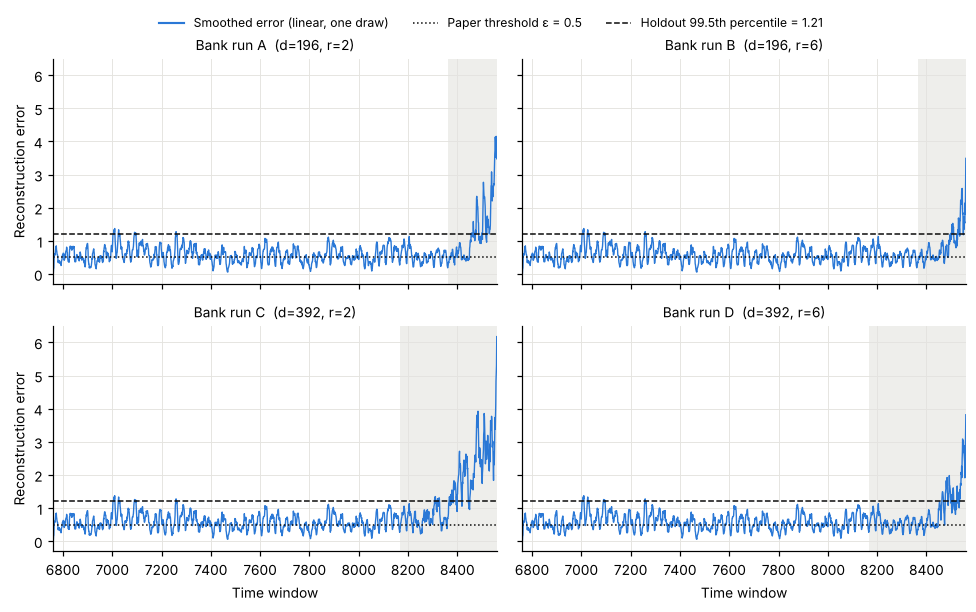

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(9, 5.4), sharex=True, sharey=True)
eps_h = thresholds["linear"]["holdout q99.5"]
for ax, name in zip(axes.ravel(), BANK_RUNS):
    run = BANK_RUNS[name]
    ax.plot(x_test, curves[(name, "linear")], color=LINEAR, lw=0.9)
    ax.axvspan(LAST - run["d"], LAST, color=GRIDC, alpha=0.6, lw=0)
    ax.axhline(EPSILON, color=INK, ls=":", lw=1.0)
    ax.axhline(eps_h, color=INK, ls="--", lw=1.0)
    ax.set_title(f"Bank run {name}  (d={run['d']}, r={run['r']})", fontsize=9)
    ax.set_xlim(TEST_START, LAST)
for ax in axes[1]: ax.set_xlabel("Time window")
for ax in axes[:, 0]: ax.set_ylabel("Reconstruction error")
handles = [plt.Line2D([], [], color=LINEAR, lw=1.4, label="Smoothed error (linear, one draw)"),
           plt.Line2D([], [], color=INK, ls=":", lw=1, label="Paper threshold ε = 0.5"),
           plt.Line2D([], [], color=INK, ls="--", lw=1, label=f"Holdout 99.5th percentile = {eps_h:.2f}")]
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.show()

**Figure 5.** Error per flow in windows 8528–8530 of run C (linear network). Rows are sending banks, columns
receiving banks; row 4 is the stressed bank. The `per_flow` draw is shown, because in the `shared` draw a window where
the coin lands on 0 receives no extra money and shows no stressed row.

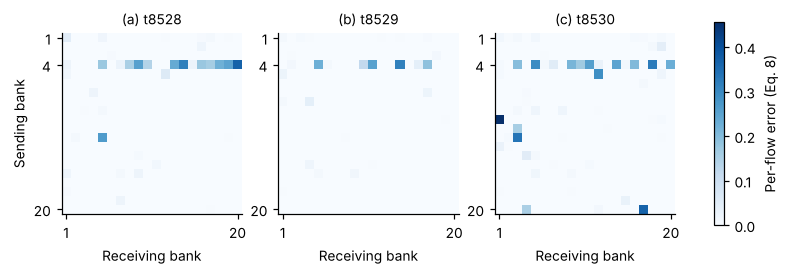

In [12]:
summary_per_flow, _, fig5 = run_experiment("per_flow", keep_curves=True)

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, e, k, lab in zip(axes, fig5, FIG5_INTERVALS, "abc"):
    im = ax.imshow(e, cmap="Blues", vmin=0, vmax=fig5.max())
    ax.set_title(f"({lab}) t{k}", fontsize=9); ax.grid(False)
    ax.set_xticks([0, 19]); ax.set_xticklabels(["1", "20"])
    ax.set_yticks([0, SUBJECT_BANK, 19]); ax.set_yticklabels(["1", str(SUBJECT_BANK + 1), "20"])
    ax.set_xlabel("Receiving bank")
axes[0].set_ylabel("Sending bank")
fig.colorbar(im, ax=axes, shrink=0.8, label="Per-flow error (Eq. 8)")
plt.show()

## 8. Sensitivity checks

1. **Reading of Equation 15:** `per_flow` (one draw per receiving bank) instead of `shared`.
2. **Which bank is stressed:** bank 1 (the largest, 58% zero flows) instead of bank 4 (86% zero flows).
3. **Injection scale** (optional, `RUN_KAPPA_SWEEP`): the paper says the amounts were "adjusted to the magnitude"
   of the stressed bank's flows, but the TARGET2 flow sizes are unknown, so every injected amount is multiplied by $\kappa$.

In [13]:
def days_table(summary, label):
    d = summary[summary.threshold == "holdout q99.5"]
    t = d.pivot(index="model", columns="run", values="first_detect_days").round(2)
    t.columns = [f"days to alarm {c}" for c in t.columns]
    r = d.pivot(index="model", columns="run", values="last_day_ratio").round(1)
    r.columns = [f"ratio {c}" for c in r.columns]
    n = d.pivot(index="model", columns="run", values="detected")
    n.columns = [f"detected {c}" for c in n.columns]
    out = pd.concat([t, r, n], axis=1); out.insert(0, "setting", label)
    return out

o = np.delete(A[:, 0, :], 0, axis=1)
print(f"bank 1: {(o == 0).mean():.1%} of outgoing flows are zero, mean non-zero flow EUR {o[o > 0].mean():,.0f}")
summary_bank1, _, _ = run_experiment("shared", bank=0)

pd.concat([days_table(summary_shared, "bank 4, shared (default)"),
           days_table(summary_per_flow, "bank 4, per_flow"),
           days_table(summary_bank1, "bank 1, shared")])

bank 1: 57.8% of outgoing flows are zero, mean non-zero flow EUR 38,615,634


,setting,days to alarm A,days to alarm B,days to alarm C,days to alarm D,ratio A,ratio B,ratio C,ratio D,detected A,detected B,detected C,detected D
model,,,,,,,,,,,,,
linear,"bank 4, shared (default)",2.87,5.02,5.23,9.71,7.4,4.6,9.2,6.6,20,20,20,20
sigmoid,"bank 4, shared (default)",2.68,4.72,3.95,9.24,9.9,6.0,12.2,8.8,20,20,20,20
linear,"bank 4, per_flow",3.37,5.59,6.76,10.48,7.0,4.6,8.5,6.2,20,20,20,20
sigmoid,"bank 4, per_flow",3.07,5.21,5.36,10.25,9.4,6.1,11.4,8.2,20,20,20,20
linear,"bank 1, shared",4.18,6.81,9.39,12.02,2.8,2.0,3.3,2.6,20,13,20,20
sigmoid,"bank 1, shared",3.64,6.11,7.49,10.81,3.9,2.7,4.7,3.6,20,20,20,20


In [14]:
if RUN_KAPPA_SWEEP:
    rows = []
    for kappa in (1, 3, 10, 30, 100):
        s_k, _, _ = run_experiment("shared", kappa=kappa)
        s_k = s_k[s_k.threshold == "holdout q99.5"]
        for _, r in s_k.iterrows():
            rows.append(dict(kappa=kappa, model=r.model, run=r.run, days=r.first_detect_days))
    display(pd.DataFrame(rows).pivot_table(index=["model", "run"], columns="kappa", values="days").round(2))
else:
    print("Skipped (set RUN_KAPPA_SWEEP = True to run).")

Skipped (set RUN_KAPPA_SWEEP = True to run).


## 9. Comparison with the paper

The paper reports its results only as figures; its values below are read from Figures 2–5.

In [ ]:
g160 = grid[grid.neurons == 160].set_index("model")
g10 = grid[grid.neurons == 10].set_index("model")
lin_best = grid[grid.model == "linear"].sort_values("holdout_mre").iloc[0]
d = summary_shared[summary_shared.threshold == "holdout q99.5"].set_index(["model", "run"])
d05 = summary_shared[summary_shared.threshold == "paper eps=0.5"].groupby("model").false_alarm.first()
days = " / ".join(f"{d.loc[('linear', r), 'first_detect_days']:.1f}" for r in "ABCD")
ratios = " / ".join(f"{d.loc[('linear', r), 'last_day_ratio']:.1f}" for r in "ABCD")
det = int(d.detected.min())

comparison = pd.DataFrame([
    ("Holdout MRE vs size", "3.1 (lin.) / 4.3 (sigm.) at l=10, about 0.55 from 160 on",
     f"{g10.loc['linear','holdout_mre']:.1f} / {g10.loc['sigmoid','holdout_mre']:.1f} at l=10; "
     f"linear {g160.loc['linear','holdout_mre']:.2f} at 160 (best {lin_best.holdout_mre:.2f} at {int(lin_best.neurons)}), "
     f"sigmoid {g160.loc['sigmoid','holdout_mre']:.2f} at 160"),
    ("Random-set MRE (l=160)", "linear about 16.7 (at the bound), sigmoid about 41",
     f"linear {g160.loc['linear','random_mre']:.1f}, sigmoid {g160.loc['sigmoid','random_mre']:.1f}"),
    ("Baseline test error", "0.2-0.5, peak 0.8 near window 7670",
     f"linear mean {base['linear'].mean():.2f} (max {base['linear'].max():.2f}), "
     f"sigmoid mean {base['sigmoid'].mean():.2f} (max {base['sigmoid'].max():.2f})"),
    ("Normal windows above 0.5", "a few peaks",
     f"linear {d05['linear']:.0%}, sigmoid {d05['sigmoid']:.1%}"),
    ("End of runs A/B/C/D", "1.0 / 0.9 / 1.1 / 0.9, about 3x baseline", f"last-day ratio (linear) {ratios}"),
    ("Detection", "all four runs visible at the end",
     f"{det} of {N_RUN_SEEDS} seeds detected for every run (holdout threshold); first alarm after {days} days (linear)"),
    ("Per-flow error map", "stressed bank's row stands out", "row 4 lights up (Figure 5 above)"),
], columns=["Result", "Paper (read from figures)", "This reproduction"])

# shown as a markdown table so long cells wrap instead of being cut off
from IPython.display import Markdown, display
rows = ["| " + " | ".join(comparison.columns) + " |", "|---|---|---|"]
rows += ["| " + " | ".join(str(v) for v in r) + " |" for r in comparison.itertuples(index=False)]
display(Markdown("\n".join(rows)))

| Result | Paper (read from figures) | This reproduction |
|---|---|---|
| Holdout MRE vs size | 3.1 (lin.) / 4.3 (sigm.) at l=10, about 0.55 from 160 on | 4.3 / 4.3 at l=10; linear 0.59 at 160 (best 0.58 at 230), sigmoid 0.25 at 160 |
| Random-set MRE (l=160) | linear about 16.7 (at the bound), sigmoid about 41 | linear 56.3, sigmoid 48.2 |
| Baseline test error | 0.2-0.5, peak 0.8 near window 7670 | linear mean 0.57 (max 1.37), sigmoid mean 0.25 (max 0.60) |
| Normal windows above 0.5 | a few peaks | linear 60%, sigmoid 2.7% |
| End of runs A/B/C/D | 1.0 / 0.9 / 1.1 / 0.9, about 3x baseline | last-day ratio (linear) 7.4 / 4.6 / 9.2 / 6.6 |
| Detection | all four runs visible at the end | 20 of 20 seeds detected for every run (holdout threshold); first alarm after 2.9 / 5.0 / 5.2 / 9.7 days (linear) |
| Per-flow error map | stressed bank's row stands out | row 4 lights up (Figure 5 above) |